# Soil Moisture Data Preparation

This notebook prepares ASM data from NASA's NSIDC-0712 dataset for next-day soil moisture prediction.

The selected validation site is 16023302. The selected period is from 15 April 2017 to 26 June 2018.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import files

uploaded = files.upload()

Saving NSIDC-0712_16023302_SMAPL2SMPE_T17350_20150401_20210331.txt to NSIDC-0712_16023302_SMAPL2SMPE_T17350_20150401_20210331.txt


In [6]:
data = pd.read_csv(
    file_name,
    skiprows=[0, 2],
    skipinitialspace=True
)
data.columns = data.columns.str.strip()

In [8]:
display(data.head())

print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))
print("Column names:")
print(data.columns.tolist())

,ID,Yr,Mo,Day,Hr,Min,TOY,WASM,ASM,WAST,...,S-FLG,SM-2,Q-FLG-2,SM-3,Q-FLG-3,SM-4,Q-FLG-4,SM-5,Q-FLG-5,ORB
0,16023302,2015,4,1,13,30,91.562,0.188,0.181,15.50,...,0,0.187,0,0.214,0,NaN,NaN,NaN,NaN,-877
1,16023302,2015,4,2,0,29,92.020,0.181,0.177,19.54,...,0,0.194,0,0.203,0,NaN,NaN,NaN,NaN,884
2,16023302,2015,4,3,13,0,93.542,0.166,0.161,16.58,...,0,0.171,0,0.176,0,NaN,NaN,NaN,NaN,-906
3,16023302,2015,4,4,0,0,94.000,0.159,0.155,17.98,...,0,0.165,0,0.178,0,NaN,NaN,NaN,NaN,913
4,16023302,2015,4,5,0,29,95.020,0.153,0.148,17.73,...,0,0.154,0,0.168,0,NaN,NaN,NaN,NaN,928


Number of rows: 2089
Number of columns: 28
Column names:
['ID', 'Yr', 'Mo', 'Day', 'Hr', 'Min', 'TOY', 'WASM', 'ASM', 'WAST', 'AST', 'sWASM', 'sASM', 'NUM', 'Q-RP', 'SM-1', 'Q-FLG-1', 'Tsurf', 'S-FLG', 'SM-2', 'Q-FLG-2', 'SM-3', 'Q-FLG-3', 'SM-4', 'Q-FLG-4', 'SM-5', 'Q-FLG-5', 'ORB']


In [9]:
print("Site IDs:", data["ID"].unique())

Site IDs: [16023302]


In [10]:
# Create a date column from year, month and day
data["Date"] = pd.to_datetime({
    "year": data["Yr"],
    "month": data["Mo"],
    "day": data["Day"]
})

display(data[["Date", "Hr", "Min", "ASM"]].head())

,Date,Hr,Min,ASM
0,2015-04-01,13,30,0.181
1,2015-04-02,0,29,0.177
2,2015-04-03,13,0,0.161
3,2015-04-04,0,0,0.155
4,2015-04-05,0,29,0.148


In [11]:
# Define the selected period
start_date = "2017-04-15"
end_date = "2018-06-26"

# Select the date and ASM values within the chosen period
selected_data = data.loc[
    (data["Date"] >= start_date) &
    (data["Date"] <= end_date),
    ["Date", "ASM"]
].copy()

# Arrange the records in chronological order
selected_data = selected_data.sort_values("Date").reset_index(drop=True)

display(selected_data.head())
display(selected_data.tail())

,Date,ASM
0,2017-04-15,0.261
1,2017-04-16,0.239
2,2017-04-17,0.235
3,2017-04-18,0.261
4,2017-04-19,0.239


,Date,ASM
429,2018-06-22,0.142
430,2018-06-23,0.157
431,2018-06-24,0.226
432,2018-06-25,0.298
433,2018-06-26,0.274


In [12]:
print("Number of selected records:", len(selected_data))
print("Start date:", selected_data["Date"].min())
print("End date:", selected_data["Date"].max())
print("Missing ASM values:", selected_data["ASM"].isna().sum())
print("Duplicate dates:", selected_data["Date"].duplicated().sum())

Number of selected records: 434
Start date: 2017-04-15 00:00:00
End date: 2018-06-26 00:00:00
Missing ASM values: 0
Duplicate dates: 0


In [13]:
# Create the complete daily date range
full_date_range = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

# Add the missing dates to the time series
processed_data = selected_data.set_index("Date")
processed_data = processed_data.reindex(full_date_range)

processed_data.index.name = "Date"

# Identify the dates without observed ASM values
missing_dates = processed_data.index[processed_data["ASM"].isna()]

print("Number of missing dates:", len(missing_dates))
print("Missing dates:")
print(missing_dates)

Number of missing dates: 4
Missing dates:
DatetimeIndex(['2018-01-17', '2018-01-18', '2018-02-10', '2018-02-12'], dtype='datetime64[ns]', name='Date', freq=None)


In [15]:
# Display the missing dates before interpolation
print("Missing dates:")
print(missing_dates)

# Estimate the missing ASM values using time-based linear interpolation
processed_data["ASM"] = processed_data["ASM"].interpolate(method="time")

# Display the estimated ASM values
display(processed_data.loc[missing_dates])

Missing dates:
DatetimeIndex(['2018-01-17', '2018-01-18', '2018-02-10', '2018-02-12'], dtype='datetime64[ns]', name='Date', freq=None)


,ASM
Date,
2018-01-17,0.155333
2018-01-18,0.154667
2018-02-10,0.141500
2018-02-12,0.141000


In [24]:
print("Number of final records:", len(processed_data))
print("Remaining missing ASM values:", processed_data["ASM"].isna().sum())

date_differences = processed_data.index.to_series().diff().dropna()

Number of final records: 438
Remaining missing ASM values: 0


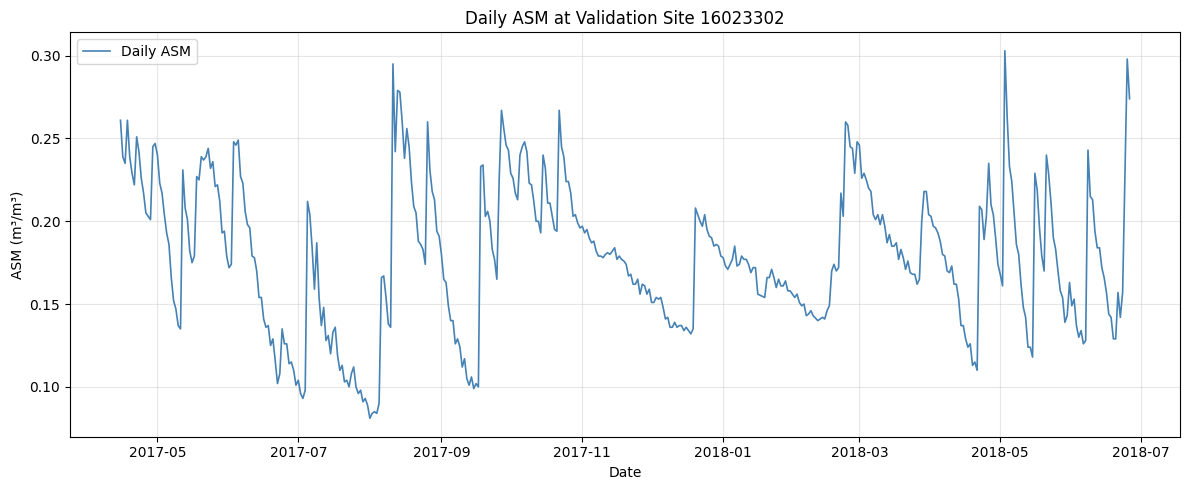

In [17]:
# Plot the complete ASM time series
plt.figure(figsize=(12, 5))

plt.plot(
    processed_data.index,
    processed_data["ASM"],
    color="steelblue",
    linewidth=1.2,
    label="Daily ASM"
)

plt.xlabel("Date")
plt.ylabel("ASM (m³/m³)")
plt.title("Daily ASM at Validation Site 16023302")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Convert the Date index back into a regular column
processed_output = processed_data.reset_index()

display(processed_output.head())

print(processed_output.columns.tolist())

,Date,ASM
0,2017-04-15,0.261
1,2017-04-16,0.239
2,2017-04-17,0.235
3,2017-04-18,0.261
4,2017-04-19,0.239


['Date', 'ASM']


In [19]:
# Save the processed data as a CSV file
output_file = "site_16023302_ASM_processed.csv"

processed_output.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d",
    float_format="%.6f"
)

print("Saved file:", output_file)

Saved file: site_16023302_ASM_processed.csv


In [20]:
# Read the saved file to verify the output
check_data = pd.read_csv(
    output_file,
    parse_dates=["Date"]
)

display(check_data.head())
display(check_data.tail())

print("Number of saved records:", len(check_data))
print("Missing ASM values:", check_data["ASM"].isna().sum())
print("Duplicate dates:", check_data["Date"].duplicated().sum())
print("Start date:", check_data["Date"].min())
print("End date:", check_data["Date"].max())

,Date,ASM
0,2017-04-15,0.261
1,2017-04-16,0.239
2,2017-04-17,0.235
3,2017-04-18,0.261
4,2017-04-19,0.239


,Date,ASM
433,2018-06-22,0.142
434,2018-06-23,0.157
435,2018-06-24,0.226
436,2018-06-25,0.298
437,2018-06-26,0.274


Number of saved records: 438
Missing ASM values: 0
Duplicate dates: 0
Start date: 2017-04-15 00:00:00
End date: 2018-06-26 00:00:00


In [21]:
from google.colab import files

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
window_size = 14

asm_values = processed_data["ASM"].values

X = []
y = []
target_dates = []

for i in range(window_size, len(asm_values)):
    X.append(asm_values[i - window_size:i])
    y.append(asm_values[i])
    target_dates.append(processed_data.index[i])

X = np.array(X)
y = np.array(y)
target_dates = np.array(target_dates)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of target dates:", len(target_dates))

X shape: (424, 14)
y shape: (424,)
Number of target dates: 424


In [25]:
num_samples = len(X)

train_end = int(num_samples * 0.70)
validation_end = int(num_samples * 0.85)

X_train = X[:train_end]
y_train = y[:train_end]
dates_train = target_dates[:train_end]

X_validation = X[train_end:validation_end]
y_validation = y[train_end:validation_end]
dates_validation = target_dates[train_end:validation_end]

X_test = X[validation_end:]
y_test = y[validation_end:]
dates_test = target_dates[validation_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Test samples:", len(X_test))

print("\nTraining period:", dates_train[0], "to", dates_train[-1])
print("Validation period:", dates_validation[0], "to", dates_validation[-1])
print("Test period:", dates_test[0], "to", dates_test[-1])

Training samples: 296
Validation samples: 64
Test samples: 64

Training period: 2017-04-29 00:00:00 to 2018-02-18 00:00:00
Validation period: 2018-02-19 00:00:00 to 2018-04-23 00:00:00
Test period: 2018-04-24 00:00:00 to 2018-06-26 00:00:00


In [26]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

training_values = asm_values[:window_size + train_end].reshape(-1, 1)
scaler.fit(training_values)

MinMaxScaler()

In [27]:
X_train_scaled = scaler.transform(
    X_train.reshape(-1, 1)
).reshape(X_train.shape)

X_validation_scaled = scaler.transform(
    X_validation.reshape(-1, 1)
).reshape(X_validation.shape)

X_test_scaled = scaler.transform(
    X_test.reshape(-1, 1)
).reshape(X_test.shape)

y_train_scaled = scaler.transform(
    y_train.reshape(-1, 1)
).flatten()

y_validation_scaled = scaler.transform(
    y_validation.reshape(-1, 1)
).flatten()

y_test_scaled = scaler.transform(
    y_test.reshape(-1, 1)
).flatten()

In [29]:
X_train_bilstm = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_validation_bilstm = X_validation_scaled.reshape(
    X_validation_scaled.shape[0],
    X_validation_scaled.shape[1],
    1
)

X_test_bilstm = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("X_train_bilstm shape:", X_train_bilstm.shape)
print("X_validation_bilstm shape:", X_validation_bilstm.shape)
print("X_test_bilstm shape:", X_test_bilstm.shape)

X_train_bilstm shape: (296, 14, 1)
X_validation_bilstm shape: (64, 14, 1)
X_test_bilstm shape: (64, 14, 1)


In [34]:
prepared_data_file = "site_16023302_model_data.npz"

np.savez_compressed(
    prepared_data_file,
    X_train=X_train_bilstm,
    y_train=y_train_scaled,
    X_validation=X_validation_bilstm,
    y_validation=y_validation_scaled,
    X_test=X_test_bilstm,
    y_test=y_test_scaled,
    dates_train=dates_train,
    dates_validation=dates_validation,
    dates_test=dates_test
)

In [31]:
import joblib

scaler_file = "site_16023302_minmax_scaler.pkl"
joblib.dump(scaler, scaler_file)

print("Saved file:", scaler_file)

Saved file: site_16023302_minmax_scaler.pkl


In [35]:
from google.colab import files

files.download(prepared_data_file)
files.download(scaler_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>